# 06 — Personalisation

Stage 3 showed that subject identity explains ~45× more feature variance than rest-vs-test (median η² 0.37 vs 0.008). This notebook asks
how much individual information helps — using only what STEW actually provides: **one rest and one test recording per subject, recorded once**.

| Approach | What the new user must provide | Supported by STEW? |
|---|---|---|
| A — subject-independent | nothing | yes |
| B1 — unsupervised subject z-score | unlabeled EEG from both states | yes (transductive) |
| B2 — rest-baseline normalisation | a ~1 min labelled resting baseline | yes (first 60 s of the rest recording) |
| C — subject-dependent | labelled data from both states | yes, within-recording only |
| D — hybrid (population + calibration) | labelled data from both states | yes, within-recording only |
| cross-session calibration | data from another day | **no — STEW has a single session; not attempted** |

**Common evaluation set.** For every subject: calibration = windows fully inside the first 60 s; evaluation = windows starting at ≥ 64 s
(a 4 s gap so no sample is shared). All approaches are scored on the *same* evaluation windows with logistic regression (C chosen in notebook 04),
so differences reflect the approach, not the model.

**Key caveat (C, D, and partly B2).** Each condition is a single continuous recording. A classifier calibrated on the first minute of each recording
and tested on later minutes can succeed by recognising *the recording* (electrode impedance, headset placement, slow drifts), not the cognitive state.
STEW cannot separate these explanations, so within-subject results are an **upper bound** on real-world calibration benefit.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

from modeling import outer_cv
from personalization import calibration_mask, evaluation_mask, subject_zscore, baseline_normalize

OUT = ROOT / "results" / "06_personalization"; OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "results" / "figures" / "06_personalization"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 160, "display.max_columns", 30)

table = pd.read_csv(ROOT / "data" / "features" / "features.csv.gz")
META_COLS = ["subject", "condition", "label", "start_s"]
meta, X = table[META_COLS].reset_index(drop=True), table.drop(columns=META_COLS).reset_index(drop=True)
y, groups = meta.label.values, meta.subject.values
best_params = json.load(open(ROOT / "results" / "04_modeling" / "summary.json"))["best_params_per_fold"]["logreg"]
C = pd.Series([eval(b)["clf__C"] for b in best_params]).mode()[0]
LR = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=C, max_iter=5000))
cal, ev = calibration_mask(meta), evaluation_mask(meta)
print(f"logistic regression C = {C}")
cnt = meta.assign(cal=cal, ev=ev).groupby(["subject", "condition"])[["cal", "ev"]].sum().unstack()
print("calibration windows per recording: median", int(np.median(cnt["cal"].values)), "| evaluation windows per recording: median", int(np.median(cnt["ev"].values)))
eligible = [s for s in meta.subject.unique() if (cnt.loc[s, "cal"] >= 5).all() and (cnt.loc[s, "ev"] >= 5).all()]
print(f"subjects with >= 5 calibration and >= 5 evaluation windows in both conditions: {len(eligible)}/48")

logistic regression C = 0.01
calibration windows per recording: median 24 | evaluation windows per recording: median 35
subjects with >= 5 calibration and >= 5 evaluation windows in both conditions: 46/48


## Run all approaches

In [2]:
Xb1 = subject_zscore(X, groups)
Xb2 = baseline_normalize(X, meta)
scores = {k: np.full(len(X), np.nan) for k in ["A_subject_independent", "B1_subject_zscore", "B2_rest_baseline", "C_subject_dependent", "D_hybrid"]}

for tr, te in outer_cv(8).split(X, y, groups):
    test_subs = [s for s in np.unique(groups[te]) if s in eligible]
    te_ev = np.flatnonzero(np.isin(groups, test_subs) & ev)
    # A: population model on raw features (all windows of training subjects)
    scores["A_subject_independent"][te_ev] = clone(LR).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te_ev])[:, 1]
    # B1: same, after unsupervised per-subject z-scoring
    scores["B1_subject_zscore"][te_ev] = clone(LR).fit(Xb1.iloc[tr], y[tr]).predict_proba(Xb1.iloc[te_ev])[:, 1]
    # B2: rest-baseline normalised; train on training subjects' non-calibration windows (mirrors the test situation)
    tr_b2 = tr[~cal[tr] & ~Xb2.iloc[tr].isna().all(axis=1).values]
    scores["B2_rest_baseline"][te_ev] = clone(LR).fit(Xb2.iloc[tr_b2], y[tr_b2]).predict_proba(Xb2.iloc[te_ev])[:, 1]
    # D: population + target calibration windows, up-weighted to ~10 subjects' worth of data
    for s in test_subs:
        s_cal = np.flatnonzero((groups == s) & cal); s_ev = np.flatnonzero((groups == s) & ev)
        w_cal = 10 * len(tr) / meta.subject.iloc[tr].nunique() / len(s_cal)
        idx = np.concatenate([tr, s_cal]); w = np.concatenate([np.ones(len(tr)), np.full(len(s_cal), w_cal)])
        m = clone(LR).fit(X.iloc[idx], y[idx], logisticregression__sample_weight=w)
        scores["D_hybrid"][s_ev] = m.predict_proba(X.iloc[s_ev])[:, 1]

# C: purely within-subject
for s in eligible:
    s_cal = np.flatnonzero((groups == s) & cal); s_ev = np.flatnonzero((groups == s) & ev)
    m = clone(LR).fit(X.iloc[s_cal], y[s_cal])
    scores["C_subject_dependent"][s_ev] = m.predict_proba(X.iloc[s_ev])[:, 1]
print("done; evaluation windows scored:", {k: int(np.isfinite(v).sum()) for k, v in scores.items()})

/opt/pyenv/versions/3.13.1/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['F3_log_var' 'F3_mobility' 'F3_complexity' 'F3_skew' 'F3_kurt'
 'F3_log_ll' 'F3_abs_delta' 'F3_abs_theta' 'F3_abs_alpha' 'F3_abs_beta'
 'F3_abs_gamma' 'F3_rel_delta' 'F3_rel_theta' 'F3_rel_alpha' 'F3_rel_beta'
 'F3_rel_gamma' 'F3_spec_ent' 'F3_r_theta_alpha' 'F3_r_theta_beta'
 'F3_r_engagement' 'faa_F4F3']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/pyenv/versions/3.13.1/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['F3_log_var' 'F3_mobility' 'F3_complexity' 'F3_skew' 'F3_kurt'
 'F3_log_ll' 'F3_abs_delta' 'F3_abs_theta' 'F3_abs_alpha' 'F3_abs_beta'
 'F3_abs_gamma' 'F3_rel_delta' 'F3_rel_theta' 'F3_rel_alpha' 'F3_rel_beta'
 'F3_rel_gamma' 'F3_spec_ent' 'F3_r_theta_alpha' 'F3_r_theta_beta'
 'F3_r_engagement' 'faa_F

done; evaluation windows scored: {'A_subject_independent': 3102, 'B1_subject_zscore': 3102, 'B2_rest_baseline': 3102, 'C_subject_dependent': 3102, 'D_hybrid': 3102}


## Results

,window_auc,window_bal_acc,recording_acc,subject_auc_median,subject_auc_mean,subjects_auc_ge_0.8,n_subjects,p_vs_A
approach,,,,,,,,
A_subject_independent,0.878,0.797,0.880,0.966,0.892,38,46,NaN
B1_subject_zscore,0.883,0.803,0.913,0.935,0.860,35,46,0.052
B2_rest_baseline,0.865,0.800,0.848,0.970,0.883,37,46,0.800
C_subject_dependent,0.982,0.948,0.989,0.999,0.985,46,46,0.000
D_hybrid,0.981,0.933,1.000,0.994,0.981,46,46,0.000


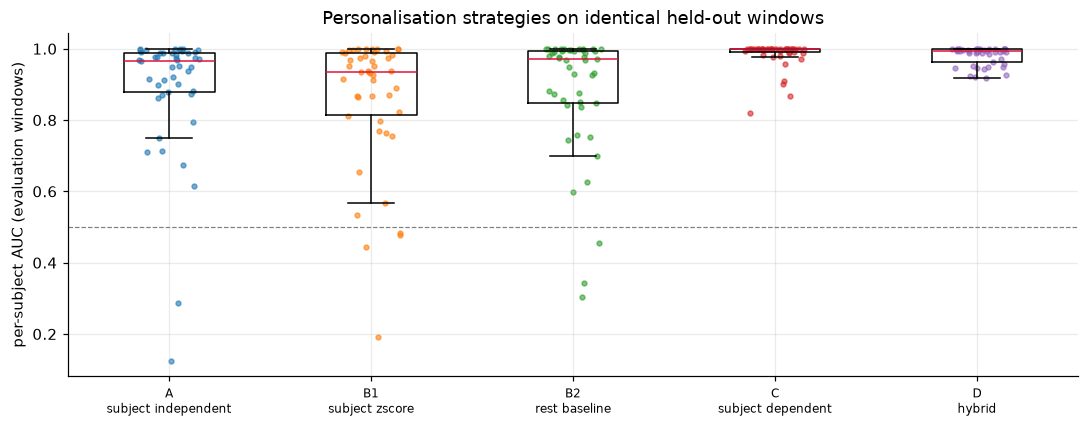

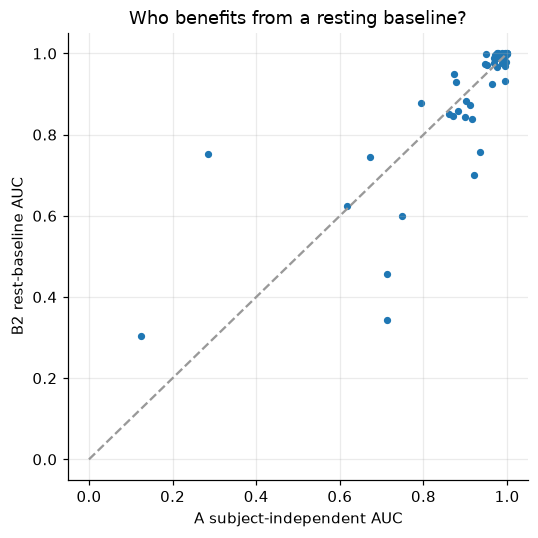

In [3]:
rows, subj = [], {}
for k, sc in scores.items():
    ok = np.isfinite(sc); d = meta[ok].assign(score=sc[ok], pred=(sc[ok] > 0.5).astype(int))
    rec = d.groupby(["subject", "condition"]).agg(label=("label", "first"), score=("score", "mean")).reset_index()
    per = d.groupby("subject").apply(lambda g: pd.Series({"auc": roc_auc_score(g.label, g.score), "bacc": balanced_accuracy_score(g.label, g.pred)}), include_groups=False)
    subj[k] = per
    rows.append({"approach": k, "window_auc": roc_auc_score(d.label, d.score), "window_bal_acc": balanced_accuracy_score(d.label, d.pred),
                 "recording_acc": ((rec.score > 0.5).astype(int) == rec.label).mean(), "subject_auc_median": per.auc.median(),
                 "subject_auc_mean": per.auc.mean(), "subjects_auc_ge_0.8": int((per.auc >= 0.8).sum()), "n_subjects": len(per)})
res = pd.DataFrame(rows).set_index("approach")
for k in res.index:
    if k != "A_subject_independent":
        res.loc[k, "p_vs_A"] = stats.wilcoxon(subj[k].auc, subj["A_subject_independent"].auc).pvalue
display(res.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
for i, k in enumerate(res.index):
    v = subj[k].auc.values
    ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.15, .15, len(v)), v, s=10, alpha=0.6)
    ax.boxplot(v, positions=[i], widths=0.45, showfliers=False, medianprops=dict(color="crimson"))
ax.axhline(0.5, color="0.5", ls="--", lw=0.8); ax.set_xticks(range(len(res)), [k.split("_", 1)[0] + "\n" + k.split("_", 1)[1].replace("_", " ") for k in res.index], fontsize=8)
ax.set_ylabel("per-subject AUC (evaluation windows)"); ax.set_title("Personalisation strategies on identical held-out windows")
fig.tight_layout(); fig.savefig(FIG_DIR / "personalization.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
a, b = subj["A_subject_independent"].auc, subj["B2_rest_baseline"].auc
ax.scatter(a, b, s=14); ax.plot([0, 1], [0, 1], color="0.6", ls="--"); ax.set_xlabel("A subject-independent AUC"); ax.set_ylabel("B2 rest-baseline AUC")
ax.set_title("Who benefits from a resting baseline?"); fig.tight_layout(); fig.savefig(FIG_DIR / "baseline_gain.png", bbox_inches="tight"); plt.show()

In [4]:
res.reset_index().to_csv(OUT / "personalization_results.csv", index=False)
pd.DataFrame({k: v.auc for k, v in subj.items()}).to_csv(OUT / "per_subject_auc.csv")
summary = {"protocol": {"calibration": "windows fully within first 60 s", "evaluation": "windows starting >= 64 s", "model": f"logistic regression C={C}",
                        "n_subjects": len(eligible), "excluded_subjects": sorted(set(range(1, 49)) - set(eligible))},
           "results": res.reset_index().to_dict(orient="records")}
with open(OUT / "summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved:", *sorted(p.name for p in OUT.iterdir()))

saved: per_subject_auc.csv personalization_results.csv summary.json


## Findings

46/48 subjects had ≥ 5 calibration and ≥ 5 evaluation windows in both conditions (sub18 and sub27 excluded); 3 102 evaluation windows scored by every approach.
(The imputer warnings above come from within-subject models where a bad channel is entirely missing; that channel is dropped consistently at fit and predict time.)

| approach | window AUC | recording acc. | median subject AUC | p vs A |
|---|---|---|---|---|
| A subject-independent | 0.878 | 0.880 | 0.966 | — |
| B1 unsupervised subject z-score | 0.883 | 0.913 | 0.935 | 0.05 |
| B2 rest-baseline (first 60 s) | 0.865 | 0.848 | 0.970 | 0.80 |
| C within-subject | 0.982 | 0.989 | 0.999 | < 0.001 |
| D hybrid | 0.981 | 1.000 | 0.994 | < 0.001 |

- **Baseline normalisation brings no reliable gain.** B1 slightly improves pooled metrics (recording accuracy 0.88 → 0.91) by removing per-subject offsets,
  but slightly *lowers* per-subject ranking (median AUC 0.966 → 0.935): z-scoring with few windows adds noise and, being computed over both conditions,
  shrinks the very contrast of interest. B2 is indistinguishable from A per subject and worse at recording level — a plausible reason is drift: the first
  minute of rest is not representative of later rest windows, so later rest windows look "less rest-like" after normalisation.
- **Within-subject calibration (C, D) is near-perfect — and should not be trusted as such.** Calibration and evaluation windows come from the same
  two continuous recordings, 4 s apart. Any stable recording-specific property (electrode contact, headset position, impedance drift) identifies the
  recording and therefore the label. STEW contains one recording per condition and one session per subject, so this cannot be disentangled from cognitive state;
  C/D are an upper bound. A real test of personalisation needs multiple blocks per condition or a second session.
- Practical conclusion: with the data available, the subject-independent model is the honest headline; personalisation is a promising direction that STEW cannot validate.
